In [27]:
import numpy as np

# 假设 bs 和 B 的值
bs = 1
B =1
size = 8
bit_size = 3

vector1 = np.random.rand(bs, 2, B, size, size, 5)
vector2 = np.random.randint(-2**(bit_size-1)+1, 2**(bit_size-1), size=(bs, 2, B, size, size, 5))
vector3 = np.zeros((bs, size, size, 2**bit_size))

# 广播和高级索引
vector1_transposed = np.transpose(vector1, (0, 3, 4, 1, 2, 5))
vector2_transposed = np.transpose(vector2, (0, 3, 4, 1, 2, 5))
print(vector1.shape, " to ", vector1_transposed.shape)
print(vector2.shape, " to ", vector2_transposed.shape)

vector1_reshaped = vector1_transposed.reshape(bs, size, size, -1)
vector2_reshaped = vector2_transposed.reshape(bs, size, size, -1)
print(vector1_transposed.shape, " to ", vector1_reshaped.shape)
print(vector2_transposed.shape, " to ", vector2_reshaped.shape)

# 将 vector2 的索引值调整为非负
vector2_reshaped = vector2_reshaped + 2**(bit_size-1)-1

np.add.at(vector3, (np.arange(bs)[:, None, None, None], np.arange(size)[None, :, None, None], np.arange(size)[None, None, :, None], vector2_reshaped), vector1_reshaped)
print(vector1_reshaped[0,0,1,:])
print(vector2_reshaped[0,0,1,:])
print(vector3[0,0,1,:])

(1, 2, 1, 8, 8, 5)  to  (1, 8, 8, 2, 1, 5)
(1, 2, 1, 8, 8, 5)  to  (1, 8, 8, 2, 1, 5)
(1, 8, 8, 2, 1, 5)  to  (1, 8, 8, 10)
(1, 8, 8, 2, 1, 5)  to  (1, 8, 8, 10)
[0.45969526 0.05629052 0.61664693 0.27116074 0.54650414 0.43993927
 0.21896768 0.89666278 0.47889405 0.06110179]
[0 5 0 4 6 6 0 2 3 3]
[1.29530987 0.         0.89666278 0.53999584 0.27116074 0.05629052
 0.9864434  0.        ]


In [28]:
import numpy as np

def diagonal_sum(a, b):
    a = np.array(a)
    b = np.array(b)
    
    n = len(a)
    
    P = np.outer(a, b)
    print(P)
    
    diagonals_sum = [np.sum(np.diag(P, k)) for k in range(-n+1, n)]
    
    return diagonals_sum

a = [0.1, 0.2, 0.3, 0.4, 0.5]
b = [0.5, 0.4, 0.3, 0.2, 0.1]

result = diagonal_sum(a, b)
print("Total diagonal sum:", result)
print("numpy.convolve:",np.convolve(a[::-1], b, mode='full'))

[[0.05 0.04 0.03 0.02 0.01]
 [0.1  0.08 0.06 0.04 0.02]
 [0.15 0.12 0.09 0.06 0.03]
 [0.2  0.16 0.12 0.08 0.04]
 [0.25 0.2  0.15 0.1  0.05]]
Total diagonal sum: [0.25, 0.4, 0.4600000000000001, 0.43999999999999995, 0.35000000000000003, 0.2, 0.1, 0.04000000000000001, 0.010000000000000002]
numpy.convolve: [0.25 0.4  0.46 0.44 0.35 0.2  0.1  0.04 0.01]


In [29]:
import numpy as np

def diagonal_sum_1(a, b):
    a = np.array(a)
    b = np.array(b)
    
    n = len(a)
    
    diagonals_sum = []
    for k in range(-n + 1, n):
        diagonals_sum.append(np.sum(a[max(0, -k):n - max(0, k)] * b[max(0, k):n - max(0, -k)]))
    
    return diagonals_sum

a = [0.1, 0.2, 0.3, 0.4, 0.5]
b = [0.5, 0.4, 0.3, 0.2, 0.1]

result = diagonal_sum_1(a, b)
print("Total diagonal sum:", result)
print("numpy.convolve:",np.convolve(a, b))

Total diagonal sum: [0.25, 0.4, 0.4600000000000001, 0.43999999999999995, 0.35000000000000003, 0.2, 0.1, 0.04000000000000001, 0.010000000000000002]
numpy.convolve: [0.05 0.14 0.26 0.4  0.55 0.4  0.26 0.14 0.05]


In [30]:
import numpy as np
import torch
import torchaudio
import torchaudio.functional as F

def diagonal_sum_2(a, b):
    a = np.array(a)
    b = np.array(b)
    
    bs, ch, B, n = a.shape
    result_shape = (bs, ch, B, 2 * n - 1)
    diagonals_sum = np.zeros(result_shape)
    
    for b_idx in range(B):
        for k in range(-n + 1, n):
            diag_sum = np.sum(
                a[:, :, b_idx, max(0, -k):n - max(0, k)] *
                b[:, :, b_idx, max(0, k):n - max(0, -k)],
                axis=-1
            )
            diagonals_sum[:, :, b_idx, k + n - 1] = diag_sum
    
    return diagonals_sum

# Example usage
a = np.random.rand(2, 3, 4, 5)
b = np.random.rand(2, 3, 4, 5)
result = diagonal_sum_2(a, b)

print("ab:", diagonal_sum_1(a[0,0,0,:], b[0,0,0,:]))
print("results[0,0,0,:]:", result[0,0,0,:])
print("results shape:", result.shape)  # Should print (2, 3, 4, 9)
# print("results",result)

a_tensor = torch.from_numpy(a[:,:,:,::-1].copy()).double()
b_tensor = torch.from_numpy(b).double()

convolved_tensor = F.convolve(a_tensor, b_tensor)
print("results shape:", convolved_tensor.shape)
print("convolved_tensor:", convolved_tensor[0,0,0,:])

ab: [0.15962394767846308, 0.21141240536297115, 0.3428606774028622, 0.7653665241609198, 1.074734980505249, 0.8412748386183609, 1.041515390585857, 1.0203387170104652, 0.3392227676596763]
results[0,0,0,:]: [0.15962395 0.21141241 0.34286068 0.76536652 1.07473498 0.84127484
 1.04151539 1.02033872 0.33922277]
results shape: (2, 3, 4, 9)
results shape: torch.Size([2, 3, 4, 9])
convolved_tensor: tensor([0.15962395, 0.21141241, 0.34286068, 0.76536652, 1.07473498, 0.84127484,
        1.04151539, 1.02033872, 0.33922277], dtype=torch.float64)


In [31]:
import numpy as np

def diagonal_sum(a, b):
    a = np.array(a)
    b = np.array(b)
    
    bs, ch, B, n = a.shape
    result_shape = (bs, ch, B, 2 * n - 1)
    
    # Apply convolution along the last axis using broadcasting
    diagonals_sum = np.apply_along_axis(
        lambda x: np.convolve(x[0], x[1], mode='full'), 
        -1, 
        np.stack((a, b), axis=-1)
    )
    
    return diagonals_sum

# Example usage
a = np.random.rand(2, 3, 4, 5)
b = np.random.rand(2, 3, 4, 5)
result = diagonal_sum(a, b)
print(result.shape)  # Should print (2, 3, 4, 9)


(2, 3, 4, 5, 1)


In [32]:
a = np.random.rand(5)
b = torch.from_numpy(a)
print("a",a)
torch.set_printoptions(profile="full")
torch.set_printoptions(threshold=float('inf'), precision=8)
print("b",b)

a [0.80663029 0.16700344 0.05551917 0.26929044 0.27811629]
b tensor([0.80663029, 0.16700344, 0.05551917, 0.26929044, 0.27811629],
       dtype=torch.float64)


In [33]:
# 假设你的张量是一个 NumPy 数组
tensor = np.random.randint(0, 10,(1, 2, 3, 5))
# 将B轴右移一位
shifted_tensor = np.roll(tensor, shift=1, axis=2)
shifted_tensor[:,:,0,:] = [1,0,0,0,0]

print(tensor)
print(shifted_tensor)

[[[[7 0 7 4 6]
   [1 4 8 4 0]
   [1 0 6 2 9]]

  [[1 5 5 4 0]
   [5 0 6 1 4]
   [2 5 7 4 1]]]]
[[[[1 0 0 0 0]
   [7 0 7 4 6]
   [1 4 8 4 0]]

  [[1 0 0 0 0]
   [1 5 5 4 0]
   [5 0 6 1 4]]]]


In [34]:
import numpy as np
# 创建两个形状为 (2, 3, 4, 5) 的示例向量
vector1 = torch.randint(0, 10, (2,3,4,5))
vector2 = torch.randint(0, 10, (2,3,4,5))

def get_diff_indexes(indexes, indexes_shifted):
    middle = indexes[:,:,:,0] - indexes_shifted[:,:,:,0] # shape: [bs,ch,B]
    diff_indexes = middle.unsqueeze(-1) # shape: [bs,ch,B,1]
    diff_indexes = diff_indexes.expand(-1, -1, -1, 2*5-1) + np.arange(-5 + 1,5) # shape: [bs,ch,B,9]
    return diff_indexes

print(get_diff_indexes(vector1,vector2).shape)

torch.Size([2, 3, 4, 9])


In [35]:
import torch
import torchaudio
import torchaudio.functional as F

# 定义两个vector A和B
a = torch.randint(0, 10, (5,))
b = torch.randint(0, 10, (5,))

c = F.convolve(a,b)
print(a)
print(b)
print(c)

tensor([7, 2, 7, 0, 3])
tensor([9, 5, 9, 2, 6])
tensor([ 63,  53, 136,  67, 136,  41,  69,   6,  18])


In [36]:
import torch 
from torch.special import entr

def calculate_entropy(tensor):
    # Calculate entropy
    entropy = -torch.sum(tensor * torch.log(tensor + 1e-10), dim=-1)  # Add a small value to avoid log(0)
    
    return entropy

# Example usage
bs = 2
size = 3
num_bit = 2
tensor = torch.rand(bs, size, size, 2**num_bit - 1)
# Ensure tensor values are probabilities
tensor = torch.softmax(tensor, dim=-1)

entropy = calculate_entropy(tensor)
entropy_2 = entr(tensor)
print(entropy)
print(-torch.sum(entropy_2,dim=-1))


tensor([[[1.07154989, 1.06910515, 1.08670521],
         [1.06943274, 1.05398834, 1.04526734],
         [1.04579270, 1.06697226, 1.06597018]],

        [[1.06437361, 1.06094444, 1.09778965],
         [1.04964352, 1.09423780, 1.06318724],
         [1.06913280, 1.09263051, 1.05891752]]])
tensor([[[-1.07154989, -1.06910515, -1.08670521],
         [-1.06943274, -1.05398834, -1.04526734],
         [-1.04579270, -1.06697226, -1.06597018]],

        [[-1.06437361, -1.06094444, -1.09778965],
         [-1.04964352, -1.09423780, -1.06318712],
         [-1.06913280, -1.09263039, -1.05891752]]])


[ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17.
 18. 19. 20. 21. 22. 23. 24. 25. 26. 27. 28. 29. 30. 31. 32. 33. 34. 35.
 36. 37. 38. 39. 40. 41. 42. 43. 44. 45. 46. 47. 48. 49. 50. 51. 52. 53.
 54. 55. 56. 57. 58. 59. 60. 61. 62. 63.]


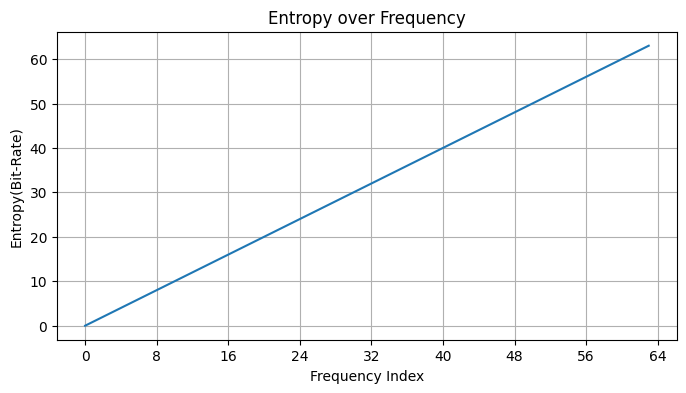

In [37]:
import matplotlib.pyplot as plt
import numpy as np

def zigzag(matrix):
    zigzag = np.array([[0, 1, 5, 6, 14, 15, 27, 28],
                           [2, 4, 7, 13, 16, 26, 29, 42],
                           [3, 8, 12, 17, 25, 30, 41, 43],
                           [9, 11, 18, 24, 31, 40, 44, 53],
                           [10, 19, 23, 32, 39, 45, 52, 54],
                           [20, 22, 33, 38, 46, 51, 55, 60],
                           [21, 34, 37, 47, 50, 56, 59, 61],
                           [35, 36, 48, 49, 57, 58, 62, 63]])

    # Get the shape of the matrix
    matrix_size = np.shape(matrix)

    # Calculate the size of the vector
    vector_size = np.shape(zigzag)

    # Check if the matrix size matches the vector size
    if matrix_size != vector_size:
        raise ValueError("The matrix size does not match the vector size.")

    # Create an empty vector to store the values
    vector = np.zeros(matrix_size[0] * matrix_size[1])

    # Iterate over each element in the matrix and place it in the corresponding position in the vector
    for i in range(matrix_size[0]):
        for j in range(matrix_size[1]):
            index = zigzag[i, j]
            vector[index] = matrix[i, j]

    return vector

def visualize_entropy(entropy):
    mean_entropy = entropy.mean(axis=0)
    flattened_entropy = zigzag(mean_entropy).flatten()
    print(flattened_entropy)
    
    # 可视化结果
    plt.figure(figsize=(8, 4))
    plt.plot(flattened_entropy)
    plt.title("Entropy over Frequency")
    plt.xlabel("Frequency Index")
    plt.ylabel("Entropy(Bit-Rate)")
    plt.xticks(np.arange(0, len(flattened_entropy)+1, 8))
    plt.grid(True)
    plt.show()

a = np.array([[[0,  1,  5,  6,  14, 15, 27, 28],
                [2,  4,  7,  13, 16, 26, 29, 42],
                [3,  8,  12, 17, 25, 30, 41, 43],
                [9,  11, 18, 24, 31, 40, 44, 53],
                [10, 19, 23, 32, 39, 45, 52, 54],
                [20, 22, 33, 38, 46, 51, 55, 60],
                [21, 34, 37, 47, 50, 56, 59, 61],
                [35, 36, 48, 49, 57, 58, 62, 63]]])
visualize_entropy(a)

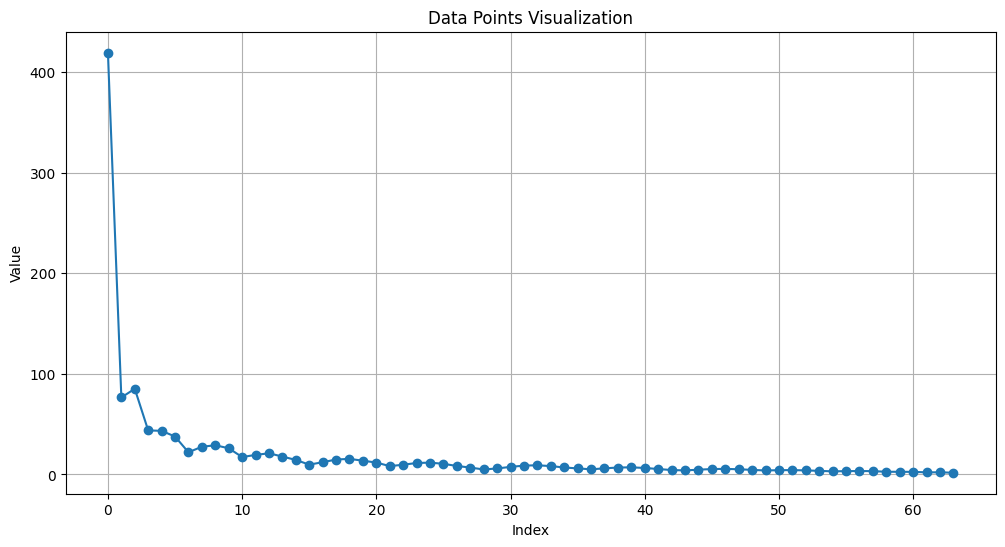

In [38]:
import matplotlib.pyplot as plt
import numpy as np

# std
data_points = [
    419.423843, 76.492424, 85.161460, 43.745250, 43.337610, 37.658657, 22.013409, 
    27.518765, 28.967226, 26.026084, 17.237013, 19.398414, 20.994909, 17.741765, 
    14.396301, 9.715402, 12.113290, 14.782494, 15.459365, 13.605389, 11.785193, 
    8.237999, 9.620348, 11.339650, 11.719138, 10.519465, 8.387234, 6.798697, 
    4.896833, 5.915232, 7.477317, 8.740592, 9.069073, 8.280509, 6.867038, 
    5.971440, 5.065986, 6.013852, 6.848645, 7.015494, 6.414611, 5.351489, 
    4.336345, 3.969943, 4.684571, 5.319590, 5.500475, 5.110037, 4.499431, 
    3.889437, 4.195618, 4.276758, 3.973427, 3.530076, 3.033488, 3.250975, 
    3.335784, 3.258849, 2.627000, 2.581992, 2.526871, 2.045730, 2.083389, 
    1.669625
]

# Plotting the data
plt.figure(figsize=(12, 6))
plt.plot(data_points, marker='o', linestyle='-')
plt.title('Data Points Visualization')
plt.xlabel('Index')
plt.ylabel('Value')
plt.grid(True)
plt.show()


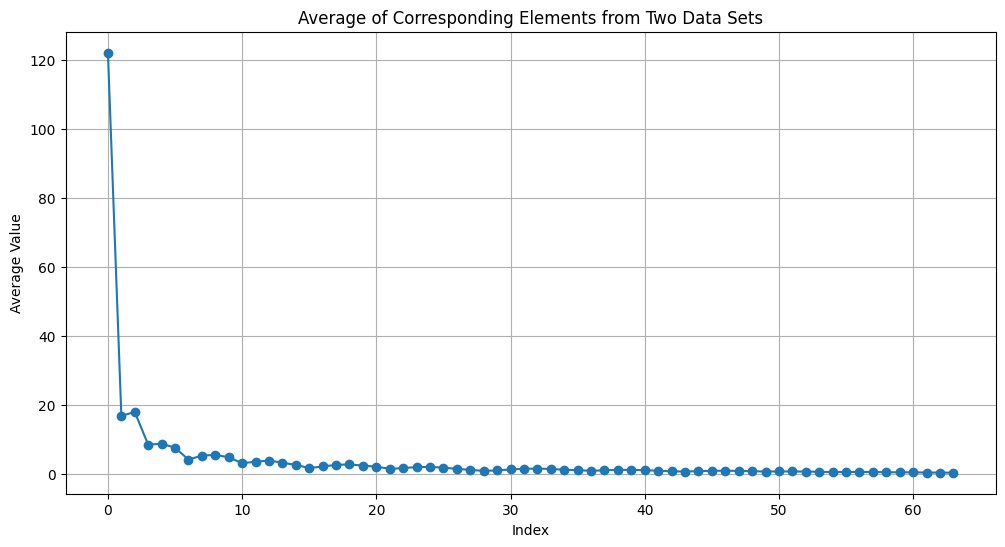

In [39]:
import numpy as np

# Data sets provided
data_set1 = [
    97.784200, 14.155302, 15.087115, 7.243579, 7.429021, 6.489650, 3.584274, 4.549016, 4.723080, 
    4.188490, 2.728058, 3.072628, 3.351419, 2.809591, 2.262201, 1.480768, 1.865847, 2.287187, 
    2.396031, 2.120911, 1.847820, 1.298597, 1.488073, 1.732288, 1.771053, 1.580715, 1.260643, 
    1.018111, 0.738565, 0.882035, 1.108156, 1.289309, 1.349915, 1.257890, 1.069399, 0.956633, 
    0.800414, 0.917484, 1.017095, 1.024408, 0.931805, 0.788675, 0.651458, 0.592522, 0.680843, 
    0.764916, 0.797368, 0.759908, 0.695176, 0.589236, 0.614871, 0.616066, 0.576045, 0.523297, 
    0.451620, 0.474205, 0.488764, 0.487785, 0.398975, 0.389411, 0.381612, 0.323609, 0.328142, 
    0.280996
]

data_set2 = [
    146.145861, 19.356185, 20.724990, 9.590588, 9.983995, 8.584846, 4.638878, 5.972495, 6.208124, 
    5.339084, 3.401065, 3.897463, 4.302123, 3.585353, 2.858700, 1.843665, 2.339246, 2.886898, 
    3.006518, 2.619313, 2.246585, 1.541796, 1.796665, 2.130480, 2.196920, 1.961460, 1.562744, 
    1.251985, 0.890423, 1.079100, 1.357199, 1.584133, 1.644738, 1.508448, 1.261287, 1.106227, 
    0.924355, 1.083069, 1.216986, 1.243082, 1.133856, 0.953085, 0.782063, 0.705648, 0.818820, 
    0.921115, 0.957210, 0.892590, 0.805775, 0.680851, 0.724536, 0.733668, 0.685166, 0.617946, 
    0.529522, 0.558977, 0.575814, 0.565560, 0.461471, 0.452334, 0.442783, 0.370460, 0.376391, 
    0.316327
]

# Calculating the average of each corresponding element
average_data = [(x + y) / 2 for x, y in zip(data_set1, data_set2)]

# Plotting the average data
plt.figure(figsize=(12, 6))
plt.plot(average_data, marker='o', linestyle='-')
plt.title('Average of Corresponding Elements from Two Data Sets')
plt.xlabel('Index')
plt.ylabel('Average Value')
plt.grid(True)
plt.show()

In [3]:
from PIL import Image
import os

def compress_image(input_path, output_path, quality):
    img = Image.open(input_path)
    img.save(output_path, 'JPEG', quality=quality)

    width, height = img.size
    file_size = os.path.getsize(output_path)
    total_pixels = width * height
    bpp = (file_size * 8) / total_pixels
    
    return bpp

def average_bpp(directory, quality):
    bpp_list = []
    for filename in os.listdir(directory):
        if filename.lower().endswith('.jpg') or filename.lower().endswith('.jpeg'):
            input_path = os.path.join(directory, filename)
            output_path = os.path.join(directory, f'compressed_{filename}')
            bpp = compress_image(input_path, output_path, quality)
            bpp_list.append(bpp)
            
            os.remove(output_path)
    
    if bpp_list:
        average_bpp = sum(bpp_list) / len(bpp_list)
        return average_bpp
    else:
        return "No JPEG images found in the directory."

directory_path  = './data/cub2011/CUB_200_2011/images/033.Yellow_billed_Cuckoo'
quality = 50

avg_bpp = average_bpp(directory_path, quality)
print(f'Average bpp for all images: {avg_bpp}')

Average bpp for all images: 1.0939914751604507
